<a href="https://colab.research.google.com/github/hubertwojcik/deep_learning/blob/main/3_ann_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from IPython import display
display.set_matplotlib_formats('svg')


/tmp/ipykernel_537/696262764.py:6: DeprecationWarning: `set_matplotlib_formats` is deprecated since IPython 7.23, directly use `matplotlib_inline.backend_inline.set_matplotlib_formats()`
  display.set_matplotlib_formats('svg')


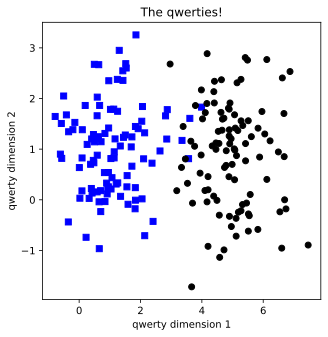

In [48]:
# create data
n_per_clust = 100
blur = 1

A = [ 1, 1]
B= [ 5, 1]

# generate data
a = [ A[0] + np.random.randn(n_per_clust) * blur, A[1] + np.random.randn(n_per_clust) * blur]
b = [B[0] + np.random.randn(n_per_clust) * blur, B[1] + np.random.randn(n_per_clust) * blur]

# true labels
labels_np = np.vstack((np.zeros((n_per_clust,1)), np.ones((n_per_clust, 1))))

#concatate into a trix
data_np = np.hstack((a,b)).T

# convert to a pytorch tensor
data = torch.tensor(data_np).float()
labels = torch.tensor(labels_np).float()

# show the data
fig = plt.figure(figsize=(5,5))
plt.plot(data[np.where(labels==0)[0],0],data[np.where(labels==0)[0],1],'bs')
plt.plot(data[np.where(labels==1)[0],0],data[np.where(labels==1)[0],1],'ko')
plt.title('The qwerties!')
plt.xlabel('qwerty dimension 1')
plt.ylabel('qwerty dimension 2')
plt.show()

In [49]:
# build the model
ann_classify = nn.Sequential(
    nn.Linear(2,1),
    nn.ReLU(),
    nn.Linear(1,1),
    nn.Sigmoid()
)


In [50]:
# model features
learning_rate = .01

# loss function
loss_fun = nn.BCELoss()

# optimizer
optimizer = torch.optim.SGD(ann_classify.parameters(), lr=learning_rate)

In [51]:
# train the model
num_epochs = 5000
losses = torch.zeros(num_epochs)

for epoch in range(num_epochs):
  y_hat = ann_classify(data)

  # compute loss
  loss = loss_fun(y_hat, labels)
  losses[epoch] = loss

  # backprop
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

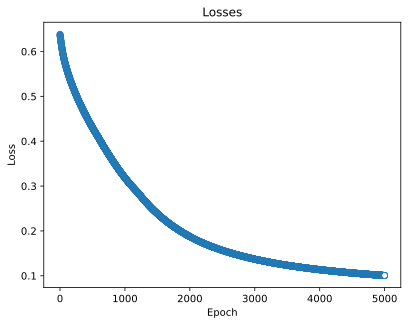

In [52]:
#. show the losses
plt.plot(losses.detach(), 'o', markerfacecolor="w", linewidth=1)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Losses')
plt.show()

In [53]:
# compute the predictions
predictions = ann_classify(data)
pred_labels = predictions > .5

# find errors
missclassified = np.where(pred_labels != labels)[0]

# total accuracy
total_acc = 100-100*len(missclassified)/(2*n_per_clust)
print(f'Total accuracy: {total_acc:.2f}%')

Total accuracy: 97.50%


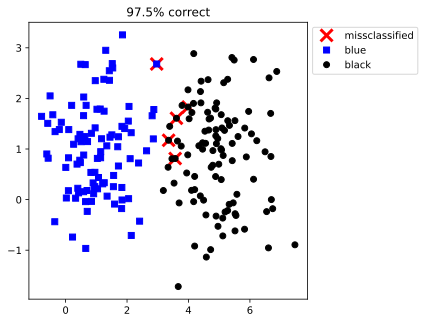

In [54]:
# plot the labeled data
fig = plt.figure(figsize=(5,5))
plt.plot(data[missclassified,0] ,data[missclassified,1],'rx',markersize=12,markeredgewidth=3)
plt.plot(data[np.where(~pred_labels)[0],0],data[np.where(~pred_labels)[0],1],'bs')
plt.plot(data[np.where(pred_labels)[0],0] ,data[np.where(pred_labels)[0],1] ,'ko')

plt.legend(['missclassified','blue','black'],bbox_to_anchor=(1,1))
plt.title(f'{total_acc}% correct')
plt.show()